In [1]:
import pandas as pd 
import numpy as np 

#Lecture du fichier et des informations 

df=pd.read_csv('stock_prices.csv')

print(df.head(-5))
print(df.shape)
print(df.info())

       symbol        date      open      high       low     close    volume
0         AAL  2014-01-02   25.0700   25.8200   25.0600   25.3600   8998943
1        AAPL  2014-01-02   79.3828   79.5756   78.8601   79.0185  58791957
2         AAP  2014-01-02  110.3600  111.8800  109.2900  109.7400    542711
3        ABBV  2014-01-02   52.1200   52.3300   51.5200   51.9800   4569061
4         ABC  2014-01-02   70.1100   70.2300   69.4800   69.8900   1148391
...       ...         ...       ...       ...       ...       ...       ...
497462   XLNX  2017-12-29   68.5000   68.7500   67.4000   67.4200    959640
497463     XL  2017-12-29   35.4500   35.4500   35.1600   35.1600   1017964
497464    XOM  2017-12-29   84.0000   84.2000   83.6400   83.6400   8523411
497465   XRAY  2017-12-29   66.3000   66.7200   65.7700   65.8300    917075
497466    XRX  2017-12-29   29.4000   29.4700   29.1200   29.1500   1537390

[497467 rows x 7 columns]
(497472, 7)
<class 'pandas.DataFrame'>
RangeIndex: 497472 ent

In [2]:
#Conversion en datetime de la colonne "date" qui était en string
df["date"]=pd.to_datetime(df["date"])
print(df.dtypes)
print(df.describe())

#Nombre de symboles
symbol_count=df['symbol'].nunique() 
print(symbol_count)

#Combien de lignes de données possède chaque action ?

print(df.groupby("symbol")["symbol"].value_counts())
print(df.groupby("symbol").size()) 

symbol               str
date      datetime64[us]
open             float64
high             float64
low              float64
close            float64
volume             int64
dtype: object
                             date           open           high  \
count                      497472  497461.000000  497464.000000   
mean   2016-01-06 17:16:00.439984      86.352275      87.132562   
min           2014-01-02 00:00:00       1.620000       1.690000   
25%           2015-01-08 00:00:00      41.690000      42.090000   
50%           2016-01-11 00:00:00      64.970000      65.560000   
75%           2017-01-06 00:00:00      98.410000      99.230000   
max           2017-12-29 00:00:00    2044.000000    2067.990000   
std                           NaN     101.471228     102.312062   

                 low          close        volume  
count  497464.000000  497472.000000  4.974720e+05  
mean       85.552467      86.369082  4.253611e+06  
min         1.500000       1.590000  0.000000e+00  

In [3]:
#recherche de doublons car 505*1007 = 508 535 et ici on a 497 472 lignes
doublons=df.duplicated().sum()
doublons_date=df.duplicated(subset=["symbol", "date"]).sum()
print(doublons)
print(doublons_date)

print("Nombre de lignes :", len(df))
print("Nombre d'actions :", df["symbol"].nunique())
print("Total des observations par action :", df.groupby("symbol").size().sum())

#Cela veut dire que pas toutes les actions ont 1007 lignes donc il faut trouver le nombre qui ont en moins 

lignes_par_actions = df.groupby("symbol").size()
actions_incompletes = lignes_par_actions[lignes_par_actions < 1007]
print(actions_incompletes)

0
0
Nombre de lignes : 497472
Nombre d'actions : 505
Total des observations par action : 497472
symbol
APTV      18
BHF      117
BHGE     126
CFG      824
CSRA     535
DHR      995
DWDP      83
DXC      189
ES       997
EVHC     271
FTV      378
GOOG     949
HLT      250
HPE      555
HPQ      555
ICE     1006
INFO     891
KHC      629
NAVI     934
O        995
PYPL     629
QRVO     755
SYF      862
UA       438
WLTW     502
WRK      636
dtype: int64


In [4]:
# Nombre de lignes où le plus haut est inférieur au plus bas pour voir la cohérence des prix 
print((df["high"] < df["low"]).sum())
anomalie_difference=df[df["high"] < df["low"]]
print(anomalie_difference)

# Nombre de lignes où la clôture est hors de l'intervalle low-high
print(((df["close"] < df["low"])|(df["close"] > df["high"])).sum())
anomalie_intervalle=df[(df["close"] < df["low"])|(df["close"] > df["high"])]
print(anomalie_intervalle)

1
      symbol       date   open    high    low   close   volume
45501    AOS 2014-05-19  23.89  23.595  23.85  24.445  1944854
9
       symbol       date     open     high      low     close   volume
45501     AOS 2014-05-19   23.890   23.595   23.850   24.4450  1944854
48774     SPG 2014-05-28  176.230  176.600  174.500  165.4200  1383759
59618     CHK 2014-06-30   30.430   31.100   30.370   29.3900  8132836
60252      IP 2014-07-01   50.850   51.070   50.570   50.0900  5624981
79814       O 2014-08-27   44.675   44.700   44.660   44.5272   185518
269985    BBY 2016-03-14   33.550   33.750   33.080   32.7200  6037794
291756    WRK 2016-05-13   42.450   42.890   41.820   38.3900  2153541
293543    LNT 2016-05-19   35.190   35.785   35.085   17.8700  1231722
301166     UA 2016-06-10   35.750   36.410   35.700   35.5400   616887


In [5]:
#données triées
df = df.sort_values(by=["symbol", "date"],ascending=True)
print(df)

       symbol       date   open    high    low  close   volume
57          A 2014-01-02  57.10  57.100  56.15  56.21  1916160
540         A 2014-01-03  56.39  57.345  56.26  56.92  1866651
1023        A 2014-01-06  57.40  57.700  56.56  56.64  1777472
1506        A 2014-01-07  56.95  57.630  56.93  57.45  1463208
1989        A 2014-01-08  57.33  58.540  57.17  58.39  2659468
...       ...        ...    ...     ...    ...    ...      ...
495451    ZTS 2017-12-22  72.30  72.370  71.79  71.99  1345683
495956    ZTS 2017-12-26  72.40  72.550  71.90  72.34   792134
496461    ZTS 2017-12-27  72.59  72.690  72.25  72.45  1159771
496966    ZTS 2017-12-28  72.49  72.600  72.14  72.39   710499
497471    ZTS 2017-12-29  72.55  72.760  72.04  72.04  1704122

[497472 rows x 7 columns]


In [ ]:
# Calcul des rendements journaliers des chacunes des actions

rendement=df.groupby("symbol")["close"].pct_change()*100

print("Nombre de NaN :", rendement.isna().sum())
print("Nombre de rendements positifs :", (rendement >= 0).sum())
print("Nombre de rendements négatifs :", (rendement < 0).sum())

# Création colonne return pour conserver ces valeurs

df["return"]=rendement
print(df.head())

# Calcul de la volatilité des actions

volatilite = df.groupby("symbol")["return"].std()*100
print(volatilite.describe())

# Affichage des 10 plus gros volatilite
top10=volatilite.sort_values(ascending=False).head(10)
print(top10)

Nombre de NaN : 505
Nombre de rendements positifs : 262242
Nombre de rendements négatifs : 234725
     symbol       date   open    high    low  close   volume    return  \
57        A 2014-01-02  57.10  57.100  56.15  56.21  1916160       NaN   
540       A 2014-01-03  56.39  57.345  56.26  56.92  1866651  1.263120   
1023      A 2014-01-06  57.40  57.700  56.56  56.64  1777472 -0.491918   
1506      A 2014-01-07  56.95  57.630  56.93  57.45  1463208  1.430085   
1989      A 2014-01-08  57.33  58.540  57.17  58.39  2659468  1.636205   

      wealth_index  running_max  drawdown  
57        1.000000     1.000000  0.000000  
540       1.012631     1.012631  0.000000  
1023      1.007650     1.012631 -0.004919  
1506      1.022060     1.022060  0.000000  
1989      1.038783     1.038783  0.000000  
count    505.000000
mean     155.893187
std       50.280202
min       82.843481
25%      122.067796
50%      143.911781
75%      175.971465
max      455.154732
Name: return, dtype: float64
symb

In [7]:
# 1. Trier les données dans l'ordre chronologique
df = df.sort_values(["symbol", "date"]).copy()

# 2. Calculer l'indice de richesse
df["wealth_index"] = (df.groupby("symbol")["return"].transform(lambda r: (1 + r.fillna(0)).cumprod()))

# 3. Trouver le sommet historique à chaque date
df["running_max"] = (df.groupby("symbol")["wealth_index"].cummax())

# 4. Calculer la baisse depuis ce sommet
df["drawdown"] = (df["wealth_index"] / df["running_max"] - 1)

# 5. Extraire la pire baisse de chaque action
max_drawdown = df.groupby("symbol")["drawdown"].min()

# 6. Afficher les 10 pires maximum drawdowns
print(max_drawdown.sort_values().head(10))

symbol
CHK     -0.949201
FCX     -0.904201
MRO     -0.838570
RRC     -0.833191
DISCK   -0.818430
DISCA   -0.817284
WMB     -0.816628
WYNN    -0.792297
UAA     -0.776945
UA      -0.768423
Name: drawdown, dtype: float64


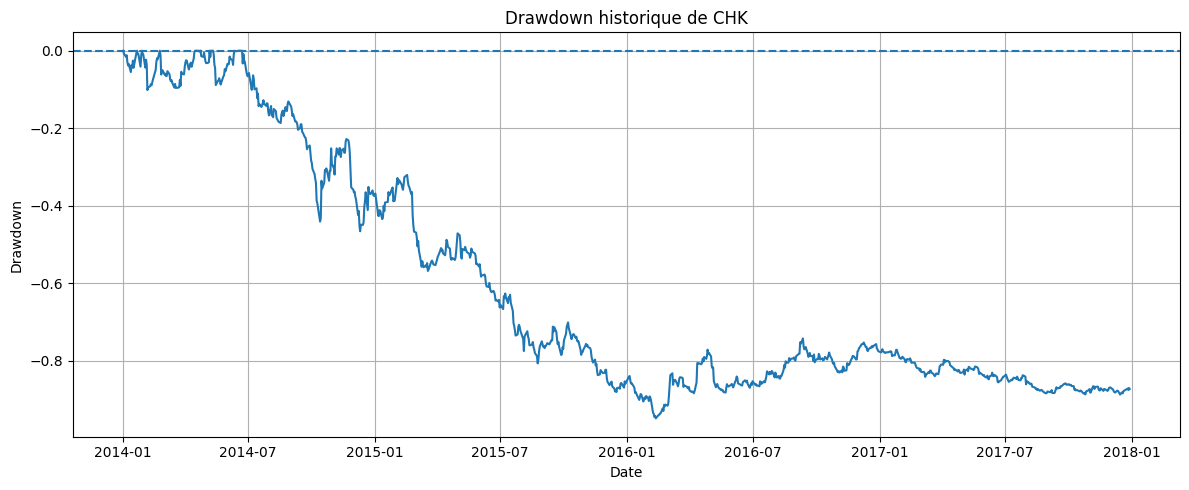

In [8]:
import matplotlib.pyplot as plt

# Sélectionner une action
ticker = "CHK"
stock = df[df["symbol"] == ticker].copy()

# Tracer le drawdown au cours du temps
plt.figure(figsize=(12, 5))
plt.plot(stock["date"], stock["drawdown"])

plt.title(f"Drawdown historique de {ticker}")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.axhline(y=0, linestyle="--")
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
### Analyse du maximum drawdown de CHK 
# L'action CHK présente un maximum drawdown de −94,92 % sur la période étudiée. La baisse la plus importante se produit entre 2015 et 2016.
# Le drawdown ne revient pas à zéro avant la fin de 2017, ce qui indique que le précédent sommet n'a pas été retrouvé durant la période d'observation.
# Ce résultat met en évidence l'importance de mesurer non seulement la volatilité des rendements, mais également l'ampleur des pertes 
# et la durée pendant laquelle un actif reste sous son précédent sommet. L'interprétation doit toutefois tenir compte de la qualité et de l'ajustement des données de prix.

In [10]:
# VaR et CvaR

# On commence l'analyse sur une action seule 

rendements = df.loc[df["symbol"] == "AAPL", "return"].dropna()
print(rendements.describe())

# Seuil du 5e percentile
seuil = rendements.quantile(0.05)

# VaR historique à 95 %
var_95 = -seuil

# Rendements dans les 5 % les plus défavorables
pires_jours = rendements[rendements <= seuil]

# CVaR historique à 95 %
cvar_95 = -pires_jours.mean()

print(f"VaR 95 % : {var_95:.2%}")
print(f"CVaR 95 % : {cvar_95:.2%}")
print(f"Nombre de jours défavorables : {len(pires_jours)}")

# La VaR historique à 95 % de l'action AAPL est estimée à 2,25 % sur une journée. Cela signifie que, sur la période historique étudiée, environ 
# 5 % des rendements journaliers sont inférieurs ou égaux à −2,25 %.
# Autrement dit, ce seuil permet d'estimer le niveau de perte journalière qui n'a été dépassé que dans environ 5 % des observations historiques.
# Cette mesure repose sur les rendements passés et ne garantit pas que les pertes futures resteront sous ce seuil.

count    1006.000000
mean        0.000860
std         0.014309
min        -0.079927
25%        -0.005858
50%         0.000493
75%         0.008176
max         0.081982
Name: return, dtype: float64
VaR 95 % : 2.25%
CVaR 95 % : 3.23%
Nombre de jours défavorables : 51


    symbol    VaR_95   CVaR_95
95     CHK  0.065491  0.097279
68    BHGE  0.030034  0.085982
182    FCX  0.054857  0.083157
32     AMD  0.051931  0.080531
486    WMB  0.037602  0.073938
320    MRO  0.046896  0.071731
453     UA  0.036557  0.069608
403    RRC  0.046225  0.065693
172   EVHC  0.032303  0.064918
341    NRG  0.037804  0.063884


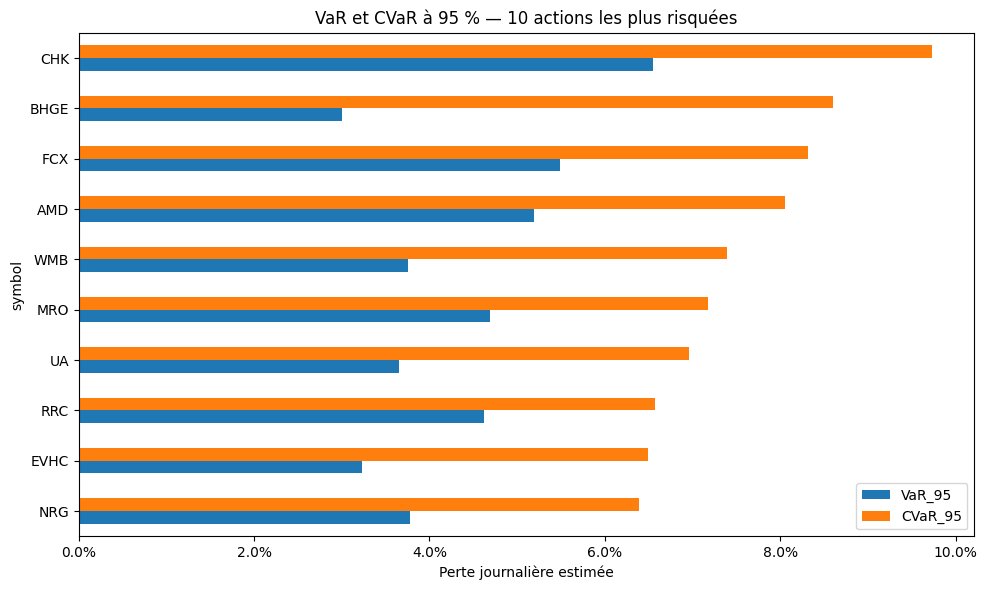

In [15]:
# On passe l'analyse sur toutes les actions 

resultats = []

for symbol, groupe in df.groupby("symbol"):

    rendements = groupe["return"].dropna()

    if len(rendements) == 0:
        continue

    seuil = rendements.quantile(0.05)

    var_95 = -seuil
    cvar_95 = -rendements[rendements <= seuil].mean()

    resultats.append({"symbol": symbol,"VaR_95": var_95,"CVaR_95": cvar_95})

risques = pd.DataFrame(resultats)

risques = risques.sort_values("CVaR_95", ascending=False)

print(risques.head(10))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

top10 = risques.head(10).sort_values("CVaR_95")

ax = top10.plot( kind="barh", x="symbol", y=["VaR_95", "CVaR_95"], figsize=(10, 6))

ax.set_xlabel("Perte journalière estimée")
ax.set_title("VaR et CVaR à 95 % — 10 actions les plus risquées")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.tight_layout()
plt.show()

In [43]:
# Detectop, des 10 rendements les plus faibles
print(df.loc[df["symbol"] == "BHGE",["date", "close", "return"]].sort_values("return").head(10))

bhge = df[df["symbol"] == "BHGE"].sort_values("date")

bhge.loc[(bhge["date"] >= pd.Timestamp("2017-06-20")) &(bhge["date"] <= pd.Timestamp("2017-07-10")),["date", "close", "return"]]

# On observe une valeur qui fosse le résultat de la moyenne de la CVaR 95%, elle peut être expliqué de part un dividende distribué.

             date  close    return
434570 2017-07-05  37.25 -0.354196
473329 2017-10-23  31.47 -0.053818
444120 2017-08-01  35.23 -0.044999
481393 2017-11-14  30.51 -0.042974
440096 2017-07-20  34.97 -0.042967
480889 2017-11-13  31.88 -0.032473
450156 2017-08-17  32.80 -0.030446
488450 2017-12-05  30.81 -0.028382
473833 2017-10-24  30.69 -0.024786
462241 2017-09-21  36.58 -0.024533


,date,close,return
434068,2017-07-03,57.68,NaN
434570,2017-07-05,37.25,-0.354196
435072,2017-07-06,37.01,-0.006443
435574,2017-07-07,37.91,0.024318
436076,2017-07-10,37.23,-0.017937


In [58]:
# BACKTESTING 
# Trier les observations chronologiquement pour chaque action

df_backtest = df.sort_values(["symbol", "date"]).copy()

# Paramètres du backtesting
fenetre = 250
alpha = 0.05

# Quantile à 5 % calculé uniquement avec les rendements précédents
df_backtest["seuil_var"] = (df_backtest.groupby("symbol")["return"].transform(lambda r: r.shift(1).rolling(window=fenetre, min_periods=fenetre).quantile(alpha)))

# Exprimer la VaR comme une perte positive
df_backtest["VaR_95"] = -df_backtest["seuil_var"]

# Une exception : rendement du jour inférieur au seuil historique
df_backtest["exception"] = (df_backtest["return"] < df_backtest["seuil_var"])

tests = df_backtest.loc[df_backtest["seuil_var"].notna()& df_backtest["return"].notna()].copy()

backtest = (tests.groupby("symbol").agg(nombre_tests=("exception", "size"),nombre_exceptions=("exception", "sum"),taux_exceptions=("exception", "mean")).reset_index())

backtest["exceptions_attendues"] = ( backtest["nombre_tests"] * alpha)

backtest = backtest.sort_values("taux_exceptions",ascending=False)

print(backtest.head(10))
# Pour ces actions, les pertes ont plus souvent dépassé le seuil de VaR que ce que prévoit le modèle. On regarde ensuite les 505.

print(backtest["taux_exceptions"].describe())

print("Nombre d'actions au-dessus de 5 % :",(backtest["taux_exceptions"] > 0.05).sum())

print("Nombre total d'actions testées :",len(backtest))

# Première hypothèse : la VaR historique sous-estime le risque pour une partie importante des actions étudiées.

    symbol  nombre_tests  nombre_exceptions  taux_exceptions  \
355   PDCO           756                 59         0.078042   
262    KIM           756                 58         0.076720   
269     KR           756                 57         0.075397   
196    GGP           756                 57         0.075397   
120    CTL           756                 55         0.072751   
341    NWL           756                 55         0.072751   
420    STX           756                 54         0.071429   
392     RL           756                 54         0.071429   
474    WDC           756                 54         0.071429   
489     XL           756                 54         0.071429   

     exceptions_attendues  
355                  37.8  
262                  37.8  
269                  37.8  
196                  37.8  
120                  37.8  
341                  37.8  
420                  37.8  
392                  37.8  
474                  37.8  
489            

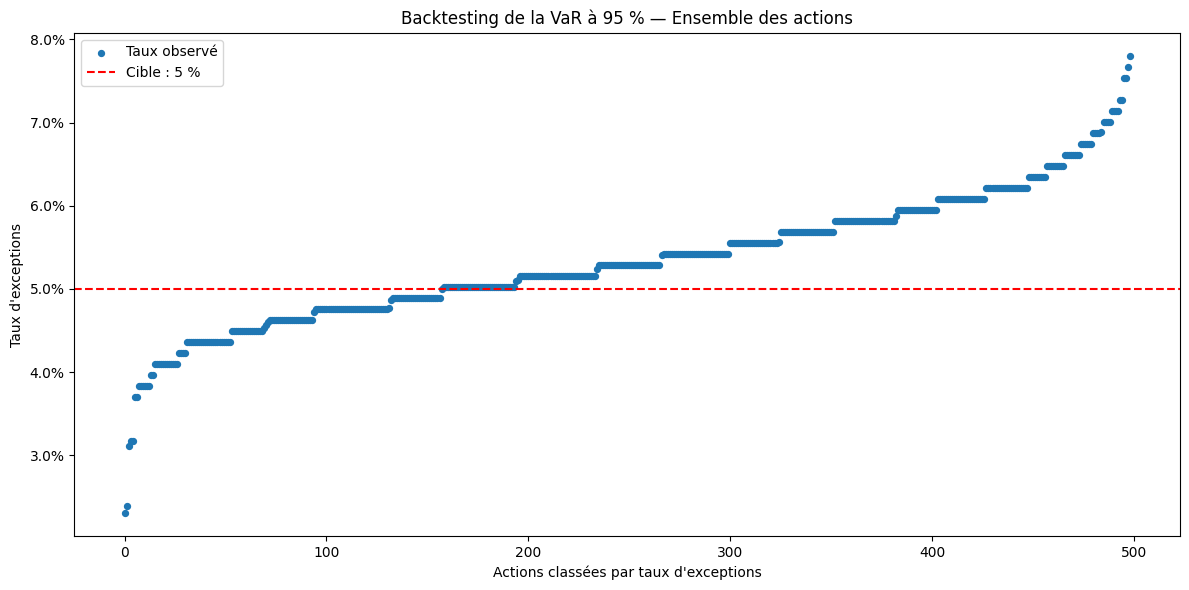

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Trier les actions par taux d'exceptions
backtest_trie = backtest.sort_values("taux_exceptions").reset_index(drop=True)

# Créer le graphique
plt.figure(figsize=(12, 6))

plt.scatter(range(len(backtest_trie)),backtest_trie["taux_exceptions"],s=18,label="Taux observé")

# Ajouter la cible théorique de 5 %
plt.axhline(y=0.05,color="red",linestyle="--",label="Cible : 5 %")

# Mettre l'axe vertical en pourcentage
plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.xlabel("Actions classées par taux d'exceptions")
plt.ylabel("Taux d'exceptions")
plt.title("Backtesting de la VaR à 95 % — Ensemble des actions")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ### Interprétation du backtesting de la VaR à 95 %

# Le backtesting utilise une fenêtre glissante de 250 rendements journaliers
# pour estimer la VaR à 95 %, puis compare les seuils estimés aux rendements
# réellement observés afin de compter les exceptions.

# En théorie, une VaR à 95 % devrait produire environ 5 % d'exceptions
# à long terme, si les hypothèses du modèle sont adaptées aux données.

# Sur les 499 actions testées, 341 présentent un taux d'exceptions supérieur
# à 5 %, soit environ 68,3 % des actions étudiées.

# Ce résultat suggère que la VaR historique sous-estime le risque de perte
# pour une partie importante des actions. Cela peut notamment s'expliquer
# par l'évolution de la volatilité : les rendements passés ne reflètent pas
# toujours suffisamment les conditions de marché à venir.

# Toutefois, un taux d'exceptions supérieur à 5 % ne prouve pas à lui seul
# que le modèle est statistiquement inadéquat. Des tests complémentaires
# seraient nécessaires pour confirmer cette conclusion.

# Enfin, les résultats doivent être interprétés en tenant compte des limites
# du dataset, notamment l'absence de confirmation concernant l'ajustement
# des cours pour les dividendes et les opérations sur titres.

# ### Conclusion

# Ce backtesting met en évidence des écarts entre le risque estimé par la VaR
# historique et les pertes journalières observées. Il souligne l'importance
# de vérifier régulièrement les modèles de risque et de tenir compte de
# l'évolution des conditions de marché.